# Deep Learning, Phase 2 (CNNs), Day 6: Transfer Learning with a Pretrained ResNet-18
Training a CNN from scratch needs lots of images and time. **Transfer learning** reuses a network that was already trained on **ImageNet** (1.2 million photos, 1,000 classes). Its early layers already detect edges, textures and shapes that are useful for almost any image task, so we only have to adapt the end of the network to our classes.

Today, with only **5,000 CIFAR-10 training images** (500 per class), we compare three ways to train the same ResNet-18:
- **A. From scratch:** random weights, everything trained.
- **B. Feature extraction:** pretrained weights **frozen**, train only a new final layer.
- **C. Fine-tuning:** also train the last residual stage (`layer4`) with a small learning rate.


In [1]:
import copy, os, sys, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import confusion_matrix, classification_report
sns.set_theme(style='whitegrid')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)
if device == 'cpu': print('WARNING: no GPU found, training will be very slow. Runtime > Change runtime type > T4 GPU.')
torch.manual_seed(0); np.random.seed(0)

Using device: cuda


## 1. Data: a small CIFAR-10 subset, prepared the ImageNet way
The pretrained network was trained with a specific input format, so we must match it:
- **Image size:** ImageNet models expect larger images than CIFAR's 32x32. We resize to `IMG = 128` (the standard is 224, but 128 is faster and works well; try 224 if you have time).
- **Normalisation:** the **ImageNet** channel means and stds (not CIFAR's own).

Subsets (stratified, so every class is equally represented): **500 images per class for training** (5,000), **100 per class for validation** (1,000, no overlap), and the **full test set** (10,000, locked until section 6). Training images get a random flip; validation and test images are not augmented.

In [2]:
IMG = 128
IM_MEAN, IM_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)                   # ImageNet statistics
tf_train = transforms.Compose([transforms.Resize(IMG), transforms.RandomHorizontalFlip(), transforms.ToTensor(), transforms.Normalize(IM_MEAN, IM_STD)])
tf_eval  = transforms.Compose([transforms.Resize(IMG), transforms.ToTensor(), transforms.Normalize(IM_MEAN, IM_STD)])
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

def cifar(train, transform):
    return datasets.CIFAR10('data', train=train, download=True, transform=transform)

raw = cifar(True, None)
labels = np.array(raw.targets if hasattr(raw, 'targets') else [raw[i][1] for i in range(len(raw))])
rng = np.random.RandomState(0)
train_idx, val_idx = [], []
for c in range(10):
    pool = rng.permutation(np.where(labels == c)[0])
    train_idx += pool[:500].tolist(); val_idx += pool[500:600].tolist()          # disjoint parts of the pool

train_set = Subset(cifar(True, tf_train), train_idx)
val_set   = Subset(cifar(True, tf_eval), val_idx)
test_set  = cifar(False, tf_eval)                                            # locked until section 6
print('Train:', len(train_set), '| Validation:', len(val_set), '| Test (locked):', len(test_set), '| image size:', IMG)

train_dl = DataLoader(train_set, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_set, batch_size=256, num_workers=2); test_dl = DataLoader(test_set, batch_size=256, num_workers=2)
xb, yb = next(iter(train_dl)); print('One batch:', xb.shape)

100%|██████████| 170M/170M [22:38<00:00, 125kB/s]


Train: 5000 | Validation: 1000 | Test (locked): 10000 | image size: 128
One batch: torch.Size([64, 3, 128, 128])


## 2. The pretrained model
`models.resnet18(weights=...)` downloads the ImageNet weights (about 45 MB). Its last layer `fc` has 1,000 outputs (ImageNet classes), so we **replace it** with a new `Linear(512, 10)` for our 10 classes. Replaced layers are trained from random values, the rest keeps the pretrained knowledge.

**Freezing** a layer = `requires_grad = False`: its weights get no gradient and the optimizer does not change them.

In [3]:
def make_resnet18(pretrained=True, train_part='all', n_classes=10, seed=0):
    torch.manual_seed(seed)
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
    m.fc = nn.Linear(m.fc.in_features, n_classes)                            # new head: 512 -> n_classes
    for name, p in m.named_parameters():
        if train_part == 'head':     p.requires_grad = name.startswith('fc')                       # feature extraction
        elif train_part == 'layer4': p.requires_grad = name.startswith(('layer4', 'fc'))           # fine-tune the last stage + head
    return m

def count(m):
    total = sum(p.numel() for p in m.parameters()); train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, train

for name, kw in [('A scratch', dict(pretrained=False)), ('B head only', dict(train_part='head')), ('C layer4 + head', dict(train_part='layer4'))]:
    t, tr = count(make_resnet18(**kw)); print(f'{name:16s} total {t:,} | trainable {tr:,} ({tr / t:.1%})')

A scratch        total 11,181,642 | trainable 11,181,642 (100.0%)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


B head only      total 11,181,642 | trainable 5,130 (0.0%)
C layer4 + head  total 11,181,642 | trainable 8,398,858 (75.1%)


## 3. Training helpers
Two details for transfer learning:
- **Different learning rates:** the new head learns with `1e-3`, pretrained layers (if unfrozen) with a smaller `1e-4`, so we do not destroy the good pretrained features.
- **Frozen batch norm:** layers whose parameters are frozen keep their batch-norm running statistics fixed (we put them in `eval()` mode), otherwise they would still change.

In [4]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, dl):
    model.eval(); tot = correct = n = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device); out = model(xb)
            tot += loss_fn(out, yb).item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return tot / n, correct / n

def train(model, epochs=5, head_lr=1e-3, backbone_lr=None, name=''):
    model.to(device)
    head = [p for n, p in model.named_parameters() if n.startswith('fc') and p.requires_grad]
    body = [p for n, p in model.named_parameters() if not n.startswith('fc') and p.requires_grad]
    groups = [{'params': head, 'lr': head_lr}] + ([{'params': body, 'lr': backbone_lr or head_lr}] if body else [])
    opt = torch.optim.Adam(groups)
    hist = {'loss': [], 'val_loss': [], 'val_acc': [], 'time': []}; best, best_state, best_ep = float('inf'), None, 0
    for ep in range(epochs):
        t0 = time.time(); model.train()
        for m in model.modules():                                                    # keep frozen batch-norm layers fixed
            if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()): m.eval()
        run = n = 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
            run += loss.item() * len(yb); n += len(yb)
        vl, va = evaluate(model, val_dl)
        for k, v in zip(hist, (run / n, vl, va, time.time() - t0)): hist[k].append(v)
        if vl < best: best, best_state, best_ep = vl, copy.deepcopy(model.state_dict()), ep + 1
        print(f'{name} epoch {ep + 1}/{epochs}  train loss {run / n:.3f}  val loss {vl:.3f}  val acc {va:.3f}  ({time.time() - t0:.1f}s)')
    model.load_state_dict(best_state); hist['best_epoch'] = best_ep; return hist

EPOCHS = 5

## 4. Three experiments on the same 5,000 images

In [5]:
model_a = make_resnet18(pretrained=False);                 h_a = train(model_a, EPOCHS, head_lr=1e-3, name='A scratch      ')

A scratch       epoch 1/5  train loss 1.808  val loss 2.354  val acc 0.276  (9.1s)
A scratch       epoch 2/5  train loss 1.536  val loss 1.834  val acc 0.359  (6.5s)
A scratch       epoch 3/5  train loss 1.403  val loss 1.533  val acc 0.433  (7.2s)
A scratch       epoch 4/5  train loss 1.288  val loss 1.440  val acc 0.494  (6.4s)
A scratch       epoch 5/5  train loss 1.184  val loss 1.657  val acc 0.457  (7.3s)


In [6]:
model_b = make_resnet18(pretrained=True, train_part='head'); h_b = train(model_b, EPOCHS, head_lr=1e-3, name='B head only    ')

B head only     epoch 1/5  train loss 1.081  val loss 0.733  val acc 0.776  (4.8s)
B head only     epoch 2/5  train loss 0.570  val loss 0.636  val acc 0.793  (4.9s)
B head only     epoch 3/5  train loss 0.494  val loss 0.602  val acc 0.806  (6.1s)
B head only     epoch 4/5  train loss 0.443  val loss 0.587  val acc 0.813  (4.9s)
B head only     epoch 5/5  train loss 0.409  val loss 0.574  val acc 0.814  (6.1s)


In [7]:
model_c = make_resnet18(pretrained=True, train_part='layer4'); h_c = train(model_c, EPOCHS, head_lr=1e-3, backbone_lr=1e-4, name='C layer4+head  ')

C layer4+head   epoch 1/5  train loss 0.733  val loss 0.440  val acc 0.847  (5.2s)
C layer4+head   epoch 2/5  train loss 0.225  val loss 0.408  val acc 0.864  (5.5s)
C layer4+head   epoch 3/5  train loss 0.103  val loss 0.419  val acc 0.871  (5.7s)
C layer4+head   epoch 4/5  train loss 0.054  val loss 0.441  val acc 0.872  (5.2s)
C layer4+head   epoch 5/5  train loss 0.034  val loss 0.440  val acc 0.875  (6.3s)


## 5. Compare on the validation set

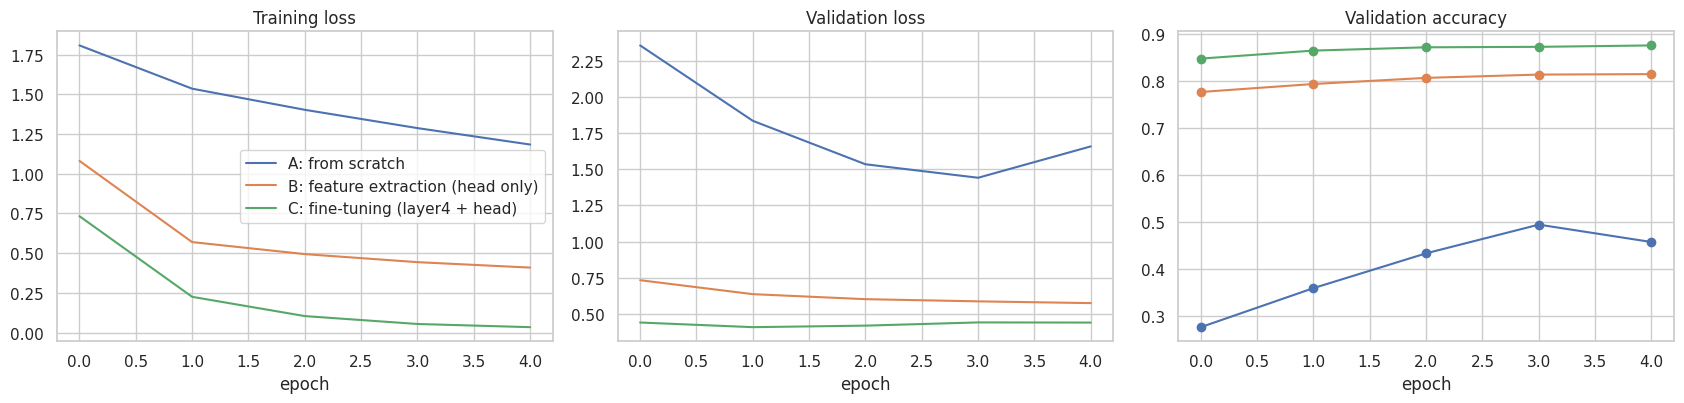

,trainable parameters,best epoch,val loss,val acc,seconds / epoch
A: from scratch,11181642.0,4.0,1.4403,0.494,7.2840
B: feature extraction (head only),5130.0,5.0,0.5745,0.814,5.3800
C: fine-tuning (layer4 + head),8398858.0,2.0,0.4083,0.864,5.5741


In [8]:
runs = {'A: from scratch': (h_a, model_a, count(model_a)[1]), 'B: feature extraction (head only)': (h_b, model_b, count(model_b)[1]),
        'C: fine-tuning (layer4 + head)': (h_c, model_c, count(model_c)[1])}
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for name, (h, _, _) in runs.items():
    ax[0].plot(h['loss'], label=name); ax[1].plot(h['val_loss'], label=name); ax[2].plot(h['val_acc'], 'o-', label=name)
ax[0].set(title='Training loss', xlabel='epoch'); ax[1].set(title='Validation loss', xlabel='epoch'); ax[2].set(title='Validation accuracy', xlabel='epoch'); ax[0].legend()
plt.tight_layout(); plt.show()
table = pd.DataFrame({name: {'trainable parameters': tp, 'best epoch': h['best_epoch'], 'val loss': evaluate(m, val_dl)[0], 'val acc': evaluate(m, val_dl)[1], 'seconds / epoch': np.mean(h['time'])}
                      for name, (h, m, tp) in runs.items()}).T.round(4); table

## 6. Final test evaluation (once)
Chosen on the validation loss; the 10,000 test images are scored once.

Chosen on the validation set: C: fine-tuning (layer4 + head)
TEST accuracy: 0.8697   TEST loss: 0.3800


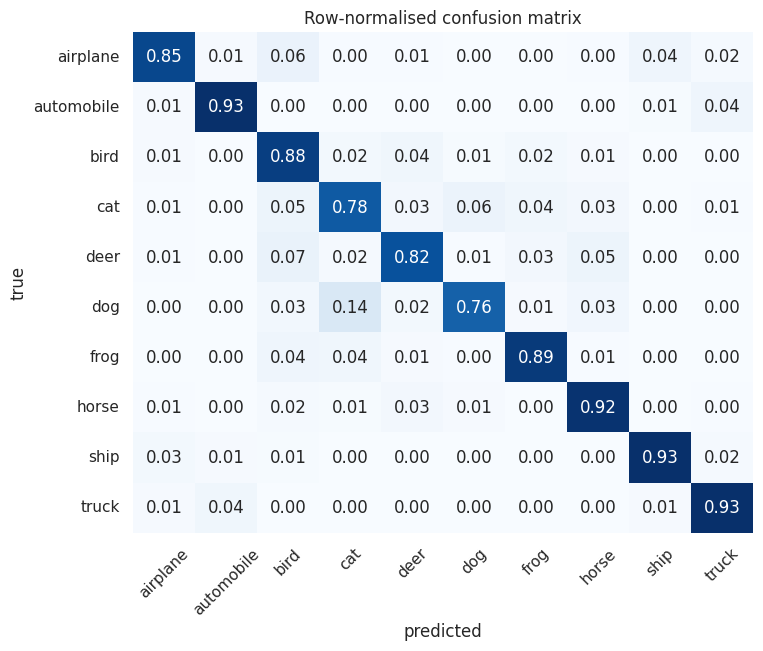

              precision    recall  f1-score   support

    airplane      0.912     0.852     0.881      1000
  automobile      0.933     0.933     0.933      1000
        bird      0.757     0.880     0.814      1000
         cat      0.768     0.780     0.774      1000
        deer      0.858     0.816     0.836      1000
         dog      0.891     0.755     0.818      1000
        frog      0.894     0.894     0.894      1000
       horse      0.868     0.922     0.894      1000
        ship      0.929     0.933     0.931      1000
       truck      0.910     0.932     0.921      1000

    accuracy                          0.870     10000
   macro avg      0.872     0.870     0.870     10000
weighted avg      0.872     0.870     0.870     10000



In [9]:
best_name = min(runs, key=lambda k: table.loc[k, 'val loss']); best_model = runs[best_name][1]
print('Chosen on the validation set:', best_name)
test_loss, test_acc = evaluate(best_model, test_dl); print(f'TEST accuracy: {test_acc:.4f}   TEST loss: {test_loss:.4f}')

best_model.eval(); preds, ytrue = [], []
with torch.no_grad():
    for xb, yb in test_dl: preds.append(best_model(xb.to(device)).argmax(1).cpu()); ytrue.append(yb)
preds, ytrue = torch.cat(preds).numpy(), torch.cat(ytrue).numpy()
cm = confusion_matrix(ytrue, preds)
plt.figure(figsize=(8, 6.5)); sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', xticklabels=classes, yticklabels=classes, cbar=False)
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('Row-normalised confusion matrix'); plt.xticks(rotation=45); plt.show()
print(classification_report(ytrue, preds, target_names=classes, digits=3))
torch.save(best_model.state_dict(), 'cifar_resnet18_transfer.pt')

## 7. Predict a single image
A trained model is only useful if you can use it on a new image: resize and normalise it exactly like the training images, run it, and read the top probabilities.

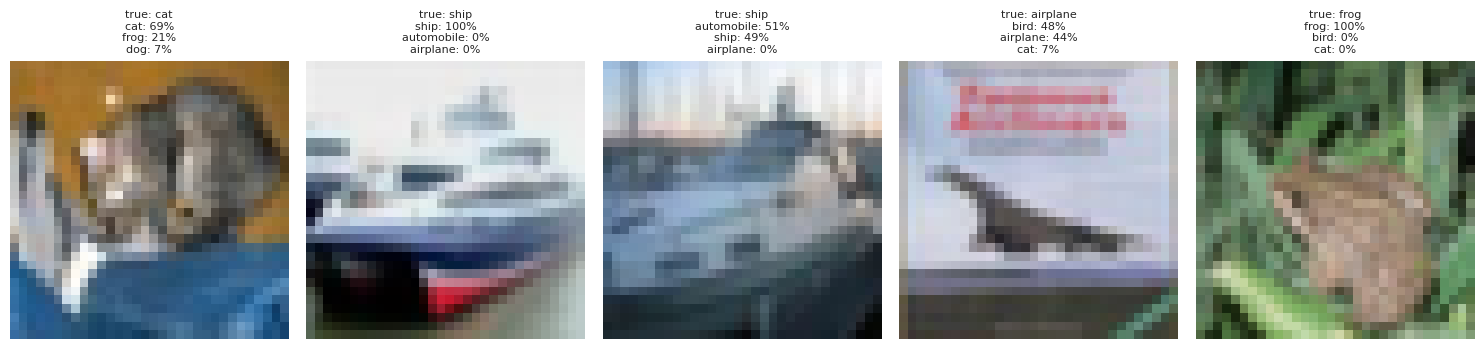

In [10]:
def predict_image(model, pil_img, topk=3):
    x = tf_eval(pil_img.convert('RGB'))[None].to(device)
    model.eval()
    with torch.no_grad(): p = torch.softmax(model(x), 1)[0].cpu()
    top = p.topk(topk); return [(classes[i], float(v)) for v, i in zip(top.values, top.indices)]

raw_test = cifar(False, None)
fig, ax = plt.subplots(1, 5, figsize=(15, 3.4))
for a, i in zip(ax, [0, 1, 2, 3, 4]):
    img, lab = raw_test[i]; res = predict_image(best_model, img)
    a.imshow(img); a.axis('off'); a.set_title('true: %s\n' % classes[lab] + '\n'.join(f'{c}: {p:.0%}' for c, p in res), fontsize=8)
plt.tight_layout(); plt.show()